# Toffoli pipeline (CircLS)

This notebook goes over the process of:
1. Creating a small logical circuit with Qiskit: a Toffoli gate on $|110\rangle$, transpiled to $H$, $T$, $T^\dagger$ and CX.
2. Writing the circuit as the OpenQASM 2 program that CircLS reads.
3. NWQEC: turning the gate list into a Pauli-based circuit, one Pauli rotation per $T$ or $T^\dagger$ followed by terminal Pauli product measurements. Every $T$ is executed as an $S$ (`t_as_s`), so the whole pipeline stays Clifford and stim can simulate it.
4. Re-selection, scheduling and gadget expansion: rewriting that list into CircLS's canonical form, with one $|Y\rangle$-ancilla gadget per rotation.
5. Mapping, routing and dynamic allocation: compiling the gadgets and the measurements with CircLS.
6. Lowering: turning the compiled program into a stim circuit; the compiled program is also saved as a JSON file.
7. Simulating the circuit: fault distance, logical error rate.

## 1. Creating a Qiskit circuit

The circuit is a Toffoli gate on $|110\rangle$ (the two $X$ gates set both controls), transpiled to $X$, $H$, $T$, $T^\dagger$ and CX: 2 Hadamards, 6 CNOTs, 4 $T$ and 3 $T^\dagger$.

In [1]:
from qiskit import QuantumCircuit, transpile

def toffoli_encoding(circuit_name: str, draw_circuit: bool = False) -> QuantumCircuit:
    """Create the Toffoli circuit on |110> in the H, T, T†, CNOT gate set."""
    qc = QuantumCircuit(3, name=circuit_name)
    for q in range(3):
        qc.reset(q)
    qc.x(0)
    qc.x(1)
    qc.ccx(0, 1, 2)
    qc = transpile(qc, basis_gates=["h", "t", "tdg", "cx", "x", "s", "sdg"], optimization_level=0)
    if draw_circuit:
        print(f"\n======> QISKIT circuit: {circuit_name.upper()}.\n", qc)
    return qc

circuit_name = "toffoli"
qc = toffoli_encoding(circuit_name, draw_circuit=True)


======> QISKIT circuit: TOFFOLI.
           ┌───┐                                             ┌───┐      
q_0: ─|0>─┤ X ├──────────────■─────────────────────■────■───┤ T ├───■──
          ├───┤              │             ┌───┐   │  ┌─┴─┐┌┴───┴┐┌─┴─┐
q_1: ─|0>─┤ X ├──■───────────┼─────────■───┤ T ├───┼──┤ X ├┤ Tdg ├┤ X ├
          ├───┤┌─┴─┐┌─────┐┌─┴─┐┌───┐┌─┴─┐┌┴───┴┐┌─┴─┐├───┤└┬───┬┘└───┘
q_2: ─|0>─┤ H ├┤ X ├┤ Tdg ├┤ X ├┤ T ├┤ X ├┤ Tdg ├┤ X ├┤ T ├─┤ H ├──────
          └───┘└───┘└─────┘└───┘└───┘└───┘└─────┘└───┘└───┘ └───┘      


## 2. The OpenQASM 2 program that CircLS reads

In [2]:
from qiskit import qasm2, ClassicalRegister

# CIRCUIT -> CIRCLS PROGRAM: the Section 1 circuit, read out in Z
qc_circls = qc.copy()
qc_circls.add_register(ClassicalRegister(3, "c"))
qc_circls.measure([0, 1, 2], [0, 1, 2])

# QISKIT -> QASM
toffoli_qasm_str = qasm2.dumps(qc_circls)
print(toffoli_qasm_str)
qasm = toffoli_qasm_str

OPENQASM 2.0;
include "qelib1.inc";
qreg q[3];
creg c[3];
reset q[0];
x q[0];
reset q[1];
x q[1];
reset q[2];
h q[2];
cx q[1],q[2];
tdg q[2];
cx q[0],q[2];
t q[2];
cx q[1],q[2];
t q[1];
tdg q[2];
cx q[0],q[2];
cx q[0],q[1];
t q[0];
tdg q[1];
cx q[0],q[1];
t q[2];
h q[2];
measure q[0] -> c[0];
measure q[1] -> c[1];
measure q[2] -> c[2];


## 3. NWQEC: from gates to Pauli rotations and Pauli product measurements

The NWQEC front end turns the original Clifford + T circuit into a sequence of Pauli rotations, followed by Pauli product measurements (PPMs).

The conversion has three steps.

**Step 1: turn every T gate into a Pauli rotation**

A T gate is itself a rotation about the Z axis (up to a global phase):

$$T_q = \exp\left(-i\frac{\pi}{8}Z_q\right)$$

For every T or T† gate in the circuit, NWQEC does the following:

1. Start from the qubit the gate acts on and initialise $P = Z_q$.
2. Find **all Clifford gates before** this T gate.
3. Starting from the Clifford gate nearest to the T gate, propagate in reverse time order. For every Clifford gate $G$ passed, update:

$$P \leftarrow G^\dagger P G$$

4. Finally, replace the T gate by:

$$\boxed{R_P = \exp\left(-i\frac{\pi}{8}P\right)}$$

If the gate was a T†, the sign of the rotation axis $P$ is flipped.

Note that for the second, third and every later T gate, **all Clifford gates before it** still count, not only the Clifford gates between two neighbouring T gates.

Earlier T gates, however, are not passed through: they have already been extracted as separate Pauli rotations.

**Step 2: turn the remaining Clifford gates into PPMs**

Once every T gate has been turned into a Pauli rotation, the Clifford gates left in the circuit can be merged into one block $C$.

Then, exactly as in the GHZ notebook, the final Z measurements are propagated backwards through this Clifford block:

$$\boxed{M_i = C^\dagger Z_i C}$$

In this way the remaining Clifford gates are absorbed into the final Pauli product measurements.

**Step 3: the final Pauli-based program**

The output of NWQEC can be written as:

$$\boxed{R_0 \to R_1 \to \cdots \to R_{k-1} \to \{M_0, M_1, \ldots\}}$$

where the Pauli rotations keep the execution order of the original T gates, and all PPMs are executed after these rotations.

The original circuit thus needs no explicit Clifford gate any more. As long as the rotation angles are unchanged, the final measurement statistics before and after the conversion are identical.

**About `t_as_s`**

This notebook uses the `t_as_s` proxy, which replaces the original π/8 rotations by π/4 rotations about the same axes:

$$\exp\left(-i\frac{\pi}{8}P\right) \longrightarrow \exp\left(-i\frac{\pi}{4}P\right)$$

This keeps the whole program Clifford, so that stim can simulate it exactly.

However, since the rotation angles change, **this proxy program is no longer equivalent to the original Toffoli circuit**.

Hence the distinction: the NWQEC conversion to Pauli rotations is itself exact, while `t_as_s` is an additional substitution introduced for testing.

In [3]:
import sys, pathlib, contextlib, io

# the CircLS checkout: the first directory at or above the working directory that holds both packages
ROOT = next(d for d in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (d / "circls").is_dir() and (d / "lightstim").is_dir())
for p in (ROOT, ROOT / "experiments", ROOT / "gallery" / "tools"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from circls.interop.nwqec.frontend import load_clifford_t_as_s
from nb_helpers import fmt_ops_plain

pbc = load_clifford_t_as_s(qasm)           # the Pauli-based circuit: rotations in circuit order, then terminal measurements
print("\n".join(fmt_ops_plain(pbc)))

(+IZX)_pi/4 rotation
(+ZZX)_pi/4 rotation
(-IZI)_pi/4 rotation
(+ZIX)_pi/4 rotation
(-ZII)_pi/4 rotation
(-ZZI)_pi/4 rotation
(+IIX)_pi/4 rotation
(-ZII) measurement
(-IZI) measurement
(+IIZ) measurement


**Derivation, gate by gate.** For a $T$ or $T^\dagger$ gate, start from its own rotation about $Z_q$ and push the axis backwards through the Clifford gates before it, latest gate first; for a terminal operator start from $Z_i$ and push it backwards through all Clifford gates. Three conjugation identities ($U^\dagger P U$ for the gate $U$) cover everything:

| gate $U$ | $U^\dagger P U$ |
|---|---|
| $H$ on $q$ | $X_q \leftrightarrow Z_q$ |
| $CX_{c,t}$ | $Z_t \to Z_cZ_t$ and $X_c \to X_cX_t$; $Z_c$ and $X_t$ are unchanged, as is every letter on another qubit |
| $X$ on $q$ (the gate) | $Z_q \to -Z_q$; $X_q$ unchanged |

The circuit in time order is $X_0$, $X_1$, $H_2$, $CX_{1,2}$, $T^\dagger_2$, $CX_{0,2}$, $T_2$, $CX_{1,2}$, $T_1$, $T^\dagger_2$, $CX_{0,2}$, $CX_{0,1}$, $T_0$, $T^\dagger_1$, $CX_{0,1}$, $T_2$, $H_2$: seven $T$-type gates and ten Clifford gates. The two $X$ gates that prepare $|110\rangle$ are the first gates, so they are the last to be pushed through, and survive only as signs.

*Rotation 0: $T^\dagger$ on $q_2$, four Clifford gates before it.*

| gate (latest first) | rotation (axis in brackets) | why |
|---|---|---|
| start | $\exp\!\big(+i\tfrac{\pi}{8}\,(Z_2)\big)$ | $T^\dagger$ on $q_2$: angle $+\pi/8$, axis $Z_2$ |
| $CX_{1,2}$ | $\exp\!\big(+i\tfrac{\pi}{8}\,(Z_1Z_2)\big)$ | $Z$ on the target picks up $Z_1$ |
| $H_2$ | $\exp\!\big(+i\tfrac{\pi}{8}\,(Z_1X_2)\big)$ | $Z_2 \to X_2$ |
| $X_1$ | $\exp\!\big(+i\tfrac{\pi}{8}\,(-Z_1X_2)\big)$ | $Z_1 \to -Z_1$ |
| $X_0$ | $\exp\!\big(+i\tfrac{\pi}{8}\,(-Z_1X_2)\big)$ | no letter on $q_0$ |
| result | $R_0 = \exp\!\big(-i\tfrac{\pi}{8}\,(+Z_1X_2)\big)$ | $T^\dagger$: the sign of the angle moves into the axis |

Under `t_as_s` this rotation is executed as $\exp\!\big(-i\tfrac{\pi}{4}\,(+Z_1X_2)\big)$, the first `pi/4 rotation` line of the printout.

*Rotation 1: $T$ on $q_2$, five Clifford gates before it.*

| gate (latest first) | rotation (axis in brackets) | why |
|---|---|---|
| start | $\exp\!\big(-i\tfrac{\pi}{8}\,(Z_2)\big)$ | $T$ on $q_2$: angle $-\pi/8$, axis $Z_2$ |
| $CX_{0,2}$ | $\exp\!\big(-i\tfrac{\pi}{8}\,(Z_0Z_2)\big)$ | $Z$ on the target picks up $Z_0$ |
| $CX_{1,2}$ | $\exp\!\big(-i\tfrac{\pi}{8}\,(Z_0Z_1Z_2)\big)$ | $Z$ on the target picks up $Z_1$ |
| $H_2$ | $\exp\!\big(-i\tfrac{\pi}{8}\,(Z_0Z_1X_2)\big)$ | $Z_2 \to X_2$ |
| $X_1$ | $\exp\!\big(-i\tfrac{\pi}{8}\,(-Z_0Z_1X_2)\big)$ | $Z_1 \to -Z_1$ |
| $X_0$ | $\exp\!\big(-i\tfrac{\pi}{8}\,(+Z_0Z_1X_2)\big)$ | $Z_0 \to -Z_0$: the two signs cancel |
| result | $R_1 = \exp\!\big(-i\tfrac{\pi}{8}\,(+Z_0Z_1X_2)\big)$ | $T$: nothing to flip |

Under `t_as_s` this rotation is executed as $\exp\!\big(-i\tfrac{\pi}{4}\,(+Z_0Z_1X_2)\big)$, the second `pi/4 rotation` line of the printout.

The other eight operators follow in the same way (a $T$ starts from $\exp(-i\frac{\pi}{8}\,(Z_q))$ and keeps its sign):

| operator | gate | Clifford gates before it | rotation / measurement |
|---|---|---|---|
| $R_0$ | $T^\dagger$ on $q_2$ | 4 | $\exp\!\big(-i\tfrac{\pi}{8}\,(+Z_1X_2)\big)$ |
| $R_1$ | $T$ on $q_2$ | 5 | $\exp\!\big(-i\tfrac{\pi}{8}\,(+Z_0Z_1X_2)\big)$ |
| $R_2$ | $T$ on $q_1$ | 6 | $\exp\!\big(-i\tfrac{\pi}{8}\,(-Z_1)\big)$ |
| $R_3$ | $T^\dagger$ on $q_2$ | 6 | $\exp\!\big(-i\tfrac{\pi}{8}\,(+Z_0X_2)\big)$ |
| $R_4$ | $T$ on $q_0$ | 8 | $\exp\!\big(-i\tfrac{\pi}{8}\,(-Z_0)\big)$ |
| $R_5$ | $T^\dagger$ on $q_1$ | 8 | $\exp\!\big(-i\tfrac{\pi}{8}\,(-Z_0Z_1)\big)$ |
| $R_6$ | $T$ on $q_2$ | 9 | $\exp\!\big(-i\tfrac{\pi}{8}\,(+X_2)\big)$ |
| $M_0$ | readout of $q_0$ | all 10 | measurement of $-Z_0$ |
| $M_1$ | readout of $q_1$ | all 10 | measurement of $-Z_1$ |
| $M_2$ | readout of $q_2$ | all 10 | measurement of $+Z_2$ |

These are the ten lines the front end printed above, in that order: the rotations $R_0, \ldots, R_6$ (printed with the `t_as_s` angle $\pi/4$), then $M_0, M_1, M_2$. The signs of $M_0 = -Z_0$ and $M_1 = -Z_1$ are the two $X$ gates: measuring $-Z$ on a patch born in $|0\rangle$ returns the bit $1$, which is how the program reads out the $|1\rangle$ controls without ever applying an $X$ gate.

In [4]:
import re
import stim

GATE = {"h": "H", "s": "S", "sdg": "S_DAG", "x": "X", "z": "Z", "cx": "CX"}   # Clifford gates; t / tdg are the rotations

def gate_list(qasm):
    """(gate, qubits) in circuit order; the leading resets are the |0> initialisation and are dropped."""
    out = []
    for line in qasm.splitlines():
        line = line.strip().rstrip(";")
        if not line or line.split()[0] in ("OPENQASM", "include", "qreg", "creg", "measure", "reset"):
            continue
        name, args = line.split(None, 1)
        out.append((name, [int(x) for x in re.findall(r"q\[(\d+)\]", args)]))
    return out

def fmt(p):
    """A stim Pauli string as a signed product with qubit indices, e.g. +Z1X2."""
    letters = "".join(f"{'_XYZ'[p[q]]}{q}" for q in range(len(p)) if p[q])
    return ("-" if p.sign == -1 else "+") + (letters or "I")

def push_back(op, gates):
    """C^dag op C: conjugate op backwards through the Clifford gates, latest gate first; keeps the gates that change it."""
    trace = [fmt(op)]
    for name, qs in reversed(gates):
        new = op.before(stim.CircuitInstruction(GATE[name], qs))
        if new != op:
            trace.append(f"-[{name} {','.join(f'q{q}' for q in qs)}]->  {fmt(new)}")
        op = new
    return op, trace

def front_end_ops(ops, n):
    out = []
    for o in ops:
        p = stim.PauliString(n)
        for q, l in o.paulis.items():
            p[q] = {"X": 1, "Y": 2, "Z": 3}[l]
        if o.sign == -1:
            p = -p
        out.append(p)
    return out

# the tables above, recomputed with stim's PauliString.before (one conjugation per gate)
print("pushing each operator backwards through the Clifford gates before it (latest gate first); gates that leave it unchanged are not shown")
gates = gate_list(qasm)
n = pbc.num_qubits
prefix, rotations_derived = [], []                 # prefix: the Clifford gates before the current gate
for name, qs in gates:
    if name in ("t", "tdg"):
        z = stim.PauliString(n)
        z[qs[0]] = 3
        op, trace = push_back(z, prefix)
        if name == "tdg":
            op = -op
            trace.append(f"-[T†]->  {fmt(op)}")
        rotations_derived.append(op)
        label = f"Rotation {len(rotations_derived) - 1} ({'T†' if name == 'tdg' else 'T '} on q{qs[0]}):"
        print(f"{label:24s}" + "  ".join(trace))
    else:
        prefix.append((name, qs))
measurements_derived = []
for i in range(n):
    z = stim.PauliString(n)
    z[i] = 3
    op, trace = push_back(z, prefix)             # all Clifford gates
    measurements_derived.append(op)
    print(f"{f'M{i} (Z readout of q{i}):':24s}" + "  ".join(trace))
front = front_end_ops(pbc.ops, n)
print("\nall 10 operators agree with the front end:", rotations_derived == front[:len(rotations_derived)] and measurements_derived == front[len(rotations_derived):])

pushing each operator backwards through the Clifford gates before it (latest gate first); gates that leave it unchanged are not shown
Rotation 0 (T† on q2):  +Z2  -[cx q1,q2]->  +Z1Z2  -[h q2]->  +Z1X2  -[x q1]->  -Z1X2  -[T†]->  +Z1X2
Rotation 1 (T  on q2):  +Z2  -[cx q0,q2]->  +Z0Z2  -[cx q1,q2]->  +Z0Z1Z2  -[h q2]->  +Z0Z1X2  -[x q1]->  -Z0Z1X2  -[x q0]->  +Z0Z1X2
Rotation 2 (T  on q1):  +Z1  -[x q1]->  -Z1
Rotation 3 (T† on q2):  +Z2  -[cx q1,q2]->  +Z1Z2  -[cx q0,q2]->  +Z0Z1Z2  -[cx q1,q2]->  +Z0Z2  -[h q2]->  +Z0X2  -[x q0]->  -Z0X2  -[T†]->  +Z0X2
Rotation 4 (T  on q0):  +Z0  -[x q0]->  -Z0
Rotation 5 (T† on q1):  +Z1  -[cx q0,q1]->  +Z0Z1  -[x q1]->  -Z0Z1  -[x q0]->  +Z0Z1  -[T†]->  -Z0Z1
Rotation 6 (T  on q2):  +Z2  -[cx q0,q2]->  +Z0Z2  -[cx q1,q2]->  +Z0Z1Z2  -[cx q0,q2]->  +Z1Z2  -[cx q1,q2]->  +Z2  -[h q2]->  +X2
M0 (Z readout of q0):   +Z0  -[x q0]->  -Z0
M1 (Z readout of q1):   +Z1  -[cx q0,q1]->  +Z0Z1  -[cx q0,q1]->  +Z1  -[x q1]->  -Z1
M2 (Z readout of q2):   +Z2  -

## 4. Canonical form: measurement re-selection, scheduling and gadget expansion

In Section 3, NWQEC turned the original Toffoli circuit into 7 Pauli rotations and 3 terminal Pauli product measurements (PPMs).

The purpose of Section 4 is to optimise these operations further and to turn every rotation into Pauli measurements that CircLS can execute by lattice surgery.

The process has three main steps.

**Step 1: measurement re-selection**

This step is exactly the same as in the GHZ notebook.

If the product of two terminal measurement operators is a Pauli operator that involves fewer patches, the original measurement can be replaced by this simpler operator, and the original outcome is recovered by a classical XOR.

For the present Toffoli circuit, the three terminal measurements are:

$$-Z_0,\qquad -Z_1,\qquad +Z_2$$

Each of them already involves a single patch, so the number of patches per measurement cannot be reduced any further.

Hence measurement re-selection changes no measurement operator here.

**Step 2: scheduling**

Scheduling reorders the Pauli rotations to reduce the number of merge windows and the routing cost as far as possible.

Two rotations can be swapped only if their Pauli axes commute.

In the present Toffoli circuit the 7 rotations contain only $Z$ on $q_0$, $q_1$ and only $X$ on $q_2$, so they commute pairwise and can be reordered freely.

For example:

$R_4 = (-Z_0)_{\pi/4}$ involves only $q_0$.

$R_0 = (+Z_1X_2)_{\pi/4}$ involves only $q_1$ and $q_2$.

Since they involve different patches, the scheduler can plan them into the same merge window.

The scheduler therefore moves $R_4$ to the front, which reduces the number of planned merge windows from 5 to 4.

Planning must be distinguished from the actual gadget execution, however.

The 5 → 4 above is the result of the scheduling stage, which only decides, from the patches each rotation involves, which operations could share a window.

In the actual compilation every rotation needs its own $|Y\rangle$-ancilla gadget, and the current CircLS does not share gadget windows that contain a $|Y\rangle$ ancilla.

Hence there are still 7 gadgets, executed in 7 consecutive windows.

In other words, scheduling improves the plan in this example but does not reduce the actual number of gadget windows; what it changes is the order in which the patches are created.

**Step 3: gadget expansion**

This is the most important step of Section 4.

CircLS executes Pauli measurements by lattice surgery; a Pauli rotation is not a native operation.

Each rotation is therefore realised by a measurement-based gadget.

For example, Section 3 gave:

$$R_0 = \exp\left(-i\frac{\pi}{4}Z_1X_2\right)$$

To execute this rotation, an ancilla qubit $y$ is introduced and initialised in:

$$|Y\rangle = \frac{|0\rangle + i|1\rangle}{\sqrt{2}}$$

Then two Pauli measurements are performed:

first: $Z_1X_2Z_y$

second: $X_y$

These two measurements, together with the necessary Pauli correction, realise the original rotation.

Why is a correction needed?

Because the two outcomes are random. Some outcomes produce the wanted rotation directly, others produce the rotation in the opposite direction.

Whether to correct is therefore decided from the outcomes.

Let the bits of the two outcomes be $b_1$ and $b_2$; the correction bit is:

$$\gamma = b_1 \oplus b_2 \oplus \kappa$$

where $\kappa = 0$ for a positive rotation and $\kappa = 1$ for a negative one.

When $\gamma = 0$, no correction is needed.

When $\gamma = 1$, a Pauli correction equal to the rotation axis is needed.

CircLS does not actually execute this correction gate; it records it in the Pauli frame.

If a later Pauli measurement anticommutes with the correction, the compiler flips that outcome by a classical XOR. If the measurement of a later gadget anticommutes with it, the correction also enters that gadget's correction condition.

No extra physical Pauli gate is executed.

So a Pauli rotation is finally turned into:

one $|Y\rangle$ ancilla, two Pauli measurements, and the corresponding classical correction rule.

**Step 4: the final result for the present Toffoli circuit**

The output of Section 3 is:

7 Pauli rotations + 3 terminal PPMs

After gadget expansion:

7 Pauli rotations → 7 gadgets

Each gadget contains two Pauli measurements, so in total:

7 × 2 = 14 gadget measurements

plus the original 3 terminal PPMs:

14 + 3 = 17 Pauli measurements

In addition, 7 $|Y\rangle$ ancillas have to be prepared.

Finally, the compiler recovers the true output of the program from the gadget corrections.

For example, the final measurement of $Z_2$ is affected by the four gadgets that contain $X_2$, because $X_2$ anticommutes with $Z_2$.

The final output bit is therefore corrected as:

$$e_2 = r_{16} \oplus \gamma_1 \oplus \gamma_2 \oplus \gamma_4 \oplus \gamma_6$$

where $r_{16}$ is the terminal measurement record and $\gamma_1, \gamma_2, \gamma_4, \gamma_6$ are the correction bits of the corresponding gadgets, numbered in the execution order after scheduling.

This shows that the output of the final program is not necessarily the raw measurement record; it also needs classical XOR corrections from the random outcomes of the earlier gadgets.

At this point the 7 Pauli rotations output by Section 3 have all been turned into measurement-based gadgets.

The final program contains 7 gadgets and 3 terminal PPMs, 17 Pauli measurements in all. CircLS can now place and route them and compile them to lattice surgery.

In [5]:
from circls.compiler.measure_reduce import reduce_measurements
from circls.interop.ir.pauli_ir import PauliCircuit

rotations = [o for o in pbc.ops if o.kind != "m"]
m_only = PauliCircuit(pbc.num_qubits, [o for o in pbc.ops if o.kind == "m"])
reduced, reconstruction = reduce_measurements(m_only)
print("original set  :", [fmt(p) for p in front_end_ops(m_only.ops, pbc.num_qubits)])
print("executed set  :", [fmt(p) for p in front_end_ops(reduced.ops, pbc.num_qubits)])
print("reconstruction: original bit k = XOR of executed bits", [sorted(inv) for inv in reconstruction.inverse], "XOR const", list(reconstruction.const))

original set  : ['-Z0', '-Z1', '+Z2']
executed set  : ['-Z0', '-Z1', '+Z2']
reconstruction: original bit k = XOR of executed bits [[0], [1], [2]] XOR const [0, 0, 0]


In [6]:
from circls.pipeline import reorder_weight1_last, drop_free_prefix, y_free_sweep, expand_gadgets
from circls.interop.ir.pauli_algebra import defer_weight1_terminal
from circls.compiler.scheduling import schedule_ops

# the passes of compile_qasm, in its order
ordered, _ = reorder_weight1_last(reduced)
stream = PauliCircuit(pbc.num_qubits, rotations + list(ordered.ops))
scheduled, perm = schedule_ops(defer_weight1_terminal(drop_free_prefix(y_free_sweep(stream)))[0], parallel=True)
program = expand_gadgets(scheduled)

print("scheduling, new position -> old position:", perm[:len(rotations)])
print("executed program:")
names = {q: (f"q{q}" if q < pbc.num_qubits else f"y{q - pbc.num_qubits}") for q in range(program.num_qubits)}
for op in program.ops:
    print(f"    {op.kind:7s} " + "  ".join(f"{names[q]}.{p}" for q, p in op.targets.items()))
print("gadgets (gamma = b1 XOR b2 XOR kappa XOR the gamma of 'conds'):")
for k, g in enumerate(program.gadgets):
    print(f"    gadget {k}: ancilla {names[g.ancilla]}, mask", {names[q]: p for q, p in g.mask.items()}, f"kappa={g.kappa}, conds={g.conds}")
print("program bits (e = record XOR flip XOR the gamma of the listed gadgets):")
for i, b in enumerate(program.out_bits):
    print(f"    e{i}: record {b.rec}, flip={b.flip}, gadgets={b.gadgets}")

scheduling, new position -> old position: [4, 0, 1, 2, 3, 5, 6]
executed program:
    init_y  y0.Y
    mpp     q0.Z  y0.Z
    mpp     y0.X
    init_y  y1.Y
    mpp     q1.Z  q2.X  y1.Z
    mpp     y1.X
    init_y  y2.Y
    mpp     q0.Z  q1.Z  q2.X  y2.Z
    mpp     y2.X
    init_y  y3.Y
    mpp     q1.Z  y3.Z
    mpp     y3.X
    init_y  y4.Y
    mpp     q0.Z  q2.X  y4.Z
    mpp     y4.X
    init_y  y5.Y
    mpp     q0.Z  q1.Z  y5.Z
    mpp     y5.X
    init_y  y6.Y
    mpp     q2.X  y6.Z
    mpp     y6.X
    mpp     q0.Z
    mpp     q1.Z
    mpp     q2.Z
gadgets (gamma = b1 XOR b2 XOR kappa XOR the gamma of 'conds'):
    gadget 0: ancilla y0, mask {'q0': 'Z'} kappa=1, conds=[]
    gadget 1: ancilla y1, mask {'q1': 'Z', 'q2': 'X'} kappa=0, conds=[]
    gadget 2: ancilla y2, mask {'q0': 'Z', 'q1': 'Z', 'q2': 'X'} kappa=0, conds=[]
    gadget 3: ancilla y3, mask {'q1': 'Z'} kappa=1, conds=[]
    gadget 4: ancilla y4, mask {'q0': 'Z', 'q2': 'X'} kappa=0, conds=[]
    gadget 5: ancilla y5,

## 5. CircLS compilation: patches, corridors, merge windows

The algorithms of this step are described in the CircLS paper ([arXiv:2608.23819](https://arxiv.org/abs/2608.23819)): where each patch is placed (mapping, Section 4.1), how the corridor of each merge is found (routing, Section 4.2), and when a patch is born and freed (dynamic allocation, Section 3). This section does not repeat them; it explains what they do on this program. The compile call below runs the paper's mapping and dynamic allocation, with the three output patches kept to the end.

**What there is to map and route.** After Section 4 the program is seven merge windows, one per gadget, each measuring the gadget's mask on one to three data patches jointly with $Z$ of its $|Y\rangle$ ancilla, followed by the three terminal $Z$ readouts, which are single-patch and need no merge:

$$\begin{aligned} \text{PPM 0: } & Z_{q_0} Z_{y_0} & \text{PPM 4: } & Z_{q_0} X_{q_2} Z_{y_4} \\ \text{PPM 1: } & Z_{q_1} X_{q_2} Z_{y_1} & \text{PPM 5: } & Z_{q_0} Z_{q_1} Z_{y_5} \\ \text{PPM 2: } & Z_{q_0} Z_{q_1} X_{q_2} Z_{y_2} & \text{PPM 6: } & X_{q_2} Z_{y_6} \\ \text{PPM 3: } & Z_{q_1} Z_{y_3} \end{aligned}$$

A window that consumes a $|Y\rangle$ ancilla is never merged with another, so the seven run one after another. Ten patches, three data and seven ancillas, go on a $9 \times 9$ grid of tiles: a patch may sit on a tile whose column and row are both odd (sixteen slots), and every even row and column is routing space.

**Mapping.** The mapper scores a layout by the estimated corridor length summed over the seven windows, improves its starting layouts (four for this program) by swapping patches and moving them to free slots, and keeps the best (Section 4.1). On this program it puts the three data patches in an L with `q1` at the corner, $(3,3)$, `q2` west of it at $(1,3)$ and `q0` south of it at $(3,5)$: `q1` shares a window with `q0` twice (PPM 2, PPM 5) and with `q2` twice (PPM 1, PPM 2), so it sits next to both, and `q0` and `q2`, which meet in PPM 2 and PPM 4, are diagonal neighbours. The seven ancillas fill the slots around the L: `y1` north of `q1`, `y2` in the corner between `q2` and `q0`, `y3` diagonal to `q1` and east of `q0`, `y5` south of `q0`, `y6` north of `q2`, `y0` and `y4` on the diagonals of `q0`. The corridors come out at $3, 3, 4, 3, 5, 5, 3$ tiles, $26$ in all.

**Routing.** For each window the router finds the smallest set of free tiles that touches a face of every patch of the window through which its letter can be measured (an exact search for windows of up to nine patches, which covers every window here; Section 4.2). The printout lists the corridor tiles of every window. PPM 1, for example, measures $Z_{q_1} X_{q_2} Z_{y_1}$ with the three tiles $(2,3)$, between `q2` and `q1`, $(2,2)$ and $(3,2)$, which reaches `y1` from the south. Tiles are reused across windows: $(2,3)$ serves PPM 1, 2 and 4, and $(2,4)$, $(2,5)$, $(4,3)$, $(4,4)$, $(4,5)$, $(4,6)$ serve two windows each. PPM 4 runs through $(1,5)$, the tile of `y2`, which is free again by then (see dynamic allocation below).

**Orientation.** A data patch is born in the orientation fixed by the letter of its first merge ($Z \to$ `X_horizontal`, $X \to$ `X_vertical`; `X_horizontal` means that the logical $\bar X$ runs along a row, so the east and west faces are the $X$-type boundaries, where a $Z$ merge attaches, and `X_vertical` is the transpose): `q0` and `q1` first appear with $Z$ (PPM 0, PPM 1) and get `X_horizontal`, `q2` first appears with $X$ (PPM 1) and gets `X_vertical`. With these orientations a $Z$ merge of `q0` or `q1` and an $X$ merge of `q2` attach through the patch's east or west face, and since every data patch is measured with its first letter in all of its windows, no patch ever has to be rotated. A $|Y\rangle$ ancilla is born in the layout of Gidney's in-place $|Y\rangle$ preparation (arXiv:2302.07395), `X_vertical`, and is measured in $Z$ through its north or south face. As in the GHZ notebook, the birth orientation of a data patch is a rule, not part of the optimisation; here the rule costs nothing.

**Dynamic allocation.** A patch is initialised at its first use: `q0` for PPM 0, in layer 1; `q1` and `q2` for PPM 1, in layer 13. Each ancilla after `y0` is allocated during the preceding window, where its $|Y\rangle$ preparation runs alongside that window's syndrome rounds; being consumed by its gadget, it is read out in $X$ three layers after its own window, once the next ancilla's preparation is complete, and its tile is freed (the printout gives the first and last layer of every patch). The three data patches are output patches and stay to the end. Freeing is what lets PPM 4 route through the tile of `y2`, consumed in PPM 2.

**How the blocks are counted.** One block is one tile occupied for $d$ measurement layers:

$$V = \frac{1}{d} \sum_{\text{tiles}} (\text{number of measurement layers during which the tile is occupied}).$$

The printout splits the sum: the ten patch tiles are occupied for $227$ tile-layers and the $17$ routing tiles for $100$. A corridor holds its tiles for the four layers of its window (three merged syndrome rounds and the corridor readout at $d = 3$), so the $26$ corridor tiles give $26 \times 4 = 104$ tile-layers, of which the $4$ on the tile of `y2` are counted with the patch tiles. Altogether $227 + 100 = 327$ tile-layers over $53$ measurement layers, and $327 / 3 = 109.0$ blocks. The $53$ layers are: one layer to initialise `q0`, four to prepare `y0`, seven windows of four layers, three layers between consecutive windows (two that complete the preparation of the next ancilla and one that reads out the ancilla just consumed), one layer to initialise `q1` and `q2` before PPM 1, and the final readout: $1 + 4 + 7 \times 4 + 6 \times 3 + 1 + 1 = 53$.

In [7]:
import circls.pipeline as P
from circls.compiler.mapping import grid_side
from circls.metrics.experiment_stats import experiment_stats
from nb_helpers import ppm_step_lines

def compile_circuit(distance, reduce=True):
    """The paper's pipeline: re-selection, T as a pi/4 gadget, the paper's mapping, first-use initialisation and last-use freeing."""
    with contextlib.redirect_stdout(io.StringIO()):
        return P.compile_qasm(qasm, distance=distance, measure_reduction=reduce, t_as_s=True,
                              assignment="optimized", liveness=True, keep_patches={"q0", "q1", "q2"})

def contiguous_runs(layers):
    """[(first, last), ...] of the maximal runs of consecutive layers."""
    runs = []
    for l in sorted(layers):
        if runs and l == runs[-1][1] + 1:
            runs[-1][1] = l
        else:
            runs.append([l, l])
    return [tuple(r) for r in runs]

def patch_layers(cp, st):
    """{patch: (birth layer, retire layer)}: the first run of layers during which the patch's own tile is occupied."""
    return {s.name: contiguous_runs(st.tile_occupancy[tuple(cp.placement[s.name])])[0] for s in cp.experiment.patches}

def window_layers(cp, st):
    """[(first, last), ...] per merge window: the layers during which all of its corridor tiles are occupied."""
    out, prev_end = [], 0
    for route in cp.routes:
        shared = set.intersection(*[set(st.tile_occupancy[tuple(t)]) for t in route])
        first, last = next(r for r in contiguous_runs(shared) if r[0] > prev_end)
        out.append((first, last))
        prev_end = last
    return out

def describe(cp):
    exp = cp.experiment
    st = experiment_stats(exp, cp.circuit)
    SEP = "-" * 80
    print("placement (patch -> tile):", cp.placement)
    print(SEP)
    print("orientation             :", {s.name: s.orientation for s in exp.patches})
    print(SEP)
    print("initial / final bases   :", dict(sorted(exp.initial_states.items())), "/", dict(sorted(exp.final_measure_states.items())))
    print(SEP)
    print("merge windows           :", len(exp.ppm_sequence))
    for line, route, (first, last) in zip(ppm_step_lines(exp.ppm_sequence), cp.routes, window_layers(cp, st)):
        print("    ", line, "  corridor tiles:", sorted(route), f"  layers {first}-{last}")
    print(SEP)
    patch_tiles = {tuple(cp.placement[s.name]) for s in exp.patches}
    on_patches = sum(len(r) for t, r in st.tile_occupancy.items() if t in patch_tiles)
    on_corridors = sum(len(r) for t, r in st.tile_occupancy.items() if t not in patch_tiles)
    print(f"spacetime volume        : {st.volume_blocks:.1f} blocks of d x d x d  "
          f"= ({on_patches} patch tile-layers + {on_corridors} tile-layers on {len(st.tile_occupancy) - len(patch_tiles)} routing tiles) / d, "
          f"over {st.circuit.measurement_layers} measurement layers; patch (first, last) layer: {patch_layers(cp, st)}")

cp3 = compile_circuit(3)
exp = cp3.experiment
describe(cp3)

placement (patch -> tile): {'q0': (3, 5), 'q1': (3, 3), 'q2': (1, 3), 'y0': (5, 7), 'y1': (3, 1), 'y2': (1, 5), 'y3': (5, 5), 'y4': (1, 7), 'y5': (3, 7), 'y6': (1, 1)}
--------------------------------------------------------------------------------
orientation             : {'q0': 'X_horizontal', 'q1': 'X_horizontal', 'q2': 'X_vertical', 'y0': 'X_vertical', 'y1': 'X_vertical', 'y2': 'X_vertical', 'y3': 'X_vertical', 'y4': 'X_vertical', 'y5': 'X_vertical', 'y6': 'X_vertical'}
--------------------------------------------------------------------------------
initial / final bases   : {'q0': 'Z', 'q1': 'Z', 'q2': 'Z', 'y0': 'Y', 'y1': 'Y', 'y2': 'Y', 'y3': 'Y', 'y4': 'Y', 'y5': 'Y', 'y6': 'Y'} / {'q0': 'Z', 'q1': 'Z', 'q2': 'Z', 'y0': 'X', 'y1': 'X', 'y2': 'X', 'y3': 'X', 'y4': 'X', 'y5': 'X', 'y6': 'X'}
--------------------------------------------------------------------------------
merge windows           : 7
     PPM 0: q0.Z  y0.Z   corridor tiles: [(4, 5), (4, 6), (5, 6)]   layers 6-9
 

## 6. The stim circuit and the compiled output file

In [8]:
circuit = cp3.circuit
print(f"d = 3: {circuit.num_qubits} qubits, {circuit.num_ticks} ticks, {circuit.num_measurements} measurements, "
      f"{circuit.num_detectors} detectors, {circuit.num_observables} observables")

d = 3: 645 qubits, 378 ticks, 2785 measurements, 2233 detectors, 5 observables


In [9]:
import json

names = {q: (f"q{q}" if q < 3 else f"y{q - 3}") for q in range(cp3.program.num_qubits)}
st = experiment_stats(exp, cp3.circuit)
live, windows = patch_layers(cp3, st), window_layers(cp3, st)

compiled = {
    "source": "toffoli", "distance": 3, "t_as_s": True,
    "grid": grid_side(len(exp.patches)),      # tiles are (column, row) on a grid of this side; patches sit on odd-odd tiles, the rest is routing space
    "patches": [{"name": s.name, "tile": list(cp3.placement[s.name]), "orientation": s.orientation,
                 "initial_basis": exp.initial_states[s.name], "final_basis": exp.final_measure_states[s.name],
                 "live_range_layers": list(live[s.name])} for s in exp.patches],   # (birth layer, retire layer)
    "ppm_sequence": [{"index": i, "operator": dict(step.interaction_type), "corridor_tiles": [list(t) for t in (route or [])], "layers": list(layers)}
                     for i, (step, route, layers) in enumerate(zip(exp.ppm_sequence, cp3.routes, windows))],
    "program": [{"kind": op.kind, "targets": {names[q]: p for q, p in op.targets.items()}} for op in cp3.program.ops],
    "gadgets": [{"ancilla": names[g.ancilla], "mask": {names[q]: p for q, p in g.mask.items()}, "kappa": g.kappa, "conds": g.conds} for g in cp3.program.gadgets],
    "out_bits": [{"record": b.rec, "flip": b.flip, "gadget_corrections": b.gadgets} for b in cp3.program.out_bits],
    "reconstruction": {"executed_bit_j_is_product_of_original": [sorted(x) for x in reconstruction.support],
                       "original_bit_k_is_xor_of_executed": [sorted(x) for x in reconstruction.inverse],
                       "const": list(reconstruction.const)},
}
path = ROOT / "notebooks" / "compiled" / "toffoli_pipeline.compiled.json"
path.parent.mkdir(exist_ok=True)
path.write_text(json.dumps(compiled, indent=1))
print(f"The compiled result is saved as {path.relative_to(ROOT)}.")

The compiled result is saved as notebooks/compiled/toffoli_pipeline.compiled.json.


In [10]:
from IPython.display import SVG

def measurement_layer_ticks(circuit):
    """Tick index of every measurement layer of the circuit, in order."""
    ticks, tick, last = [], 0, None
    for inst in circuit.flattened():
        if inst.name == "TICK":
            tick += 1
        elif inst.name.startswith("M") and tick != last:
            ticks.append(tick)
            last = tick
    return ticks

# merge window PPM 1 (the whole circuit is too long to draw), from the layer in which its corridor is reset to the layer
# in which it is read out; layers are 1-indexed, and the corridor is reset in the layer before its first merged round
first, last = windows[1]
layer_tick = measurement_layer_ticks(circuit)
window = range(layer_tick[first - 2], layer_tick[last - 1] + 1)
print(f"PPM 1: measurement layers {first}-{last}, ticks {window.start}-{window.stop - 1}")
display(SVG(str(circuit.diagram("detslice-with-ops-svg", tick=window))))

PPM 1: measurement layers 14-17, ticks 94-126


## 7. Simulation: fault distance and logical error rate

In [11]:
from noise_inject import inject_uniform_noise

DISTANCES = (3, 5)
circuits = {d: compile_circuit(d).circuit for d in DISTANCES}      # compiled once here, sampled below
for d, circ in circuits.items():
    noisy = inject_uniform_noise(circ, 1e-3)
    dist = len(noisy.shortest_graphlike_error(ignore_ungraphlike_errors=False))
    print(f"d = {d}: {circ.num_qubits:4d} qubits, {circ.num_detectors:5d} detectors, "
          f"{circ.num_observables} observables, graphlike fault distance = {dist}")

d = 3:  645 qubits,  2233 detectors, 5 observables, graphlike fault distance = 3


d = 5: 1629 qubits,  9522 detectors, 5 observables, graphlike fault distance = 5


In [12]:
import pymatching
import numpy as np

P_VALUES = (1e-4, 2e-4, 3e-4, 5e-4, 7e-4, 1e-3)          # a lower range than the GHZ notebook: this circuit is about fifty times larger
MIN_ERRORS, BATCH, MAX_SHOTS = 100, 100_000, 500_000

def logical_error_rate(circuit, p):
    """MWPM decoding; sample until MIN_ERRORS logical errors or MAX_SHOTS shots. Returns (errors, shots)."""
    noisy = inject_uniform_noise(circuit, p)
    matcher = pymatching.Matching.from_detector_error_model(noisy.detector_error_model(decompose_errors=True))
    sampler = noisy.compile_detector_sampler(seed=0)
    shots = errors = 0
    while errors < MIN_ERRORS and shots < MAX_SHOTS:
        det, obs = sampler.sample(BATCH, separate_observables=True)
        errors += int(np.any(matcher.decode_batch(det) != obs, axis=1).sum())
        shots += BATCH
    return errors, shots

results = {}
for d in DISTANCES:
    results[d] = [logical_error_rate(circuits[d], p) for p in P_VALUES]
    for p, (errors, shots) in zip(P_VALUES, results[d]):
        print(f"d = {d}, p = {p:.0e}: LER = {errors / shots:.2e}  ({errors} / {shots})")

d = 3, p = 1e-04: LER = 5.16e-03  (516 / 100000)
d = 3, p = 2e-04: LER = 1.88e-02  (1885 / 100000)
d = 3, p = 3e-04: LER = 4.05e-02  (4051 / 100000)
d = 3, p = 5e-04: LER = 1.05e-01  (10480 / 100000)
d = 3, p = 7e-04: LER = 1.87e-01  (18726 / 100000)
d = 3, p = 1e-03: LER = 3.19e-01  (31870 / 100000)


d = 5, p = 1e-04: LER = 1.40e-04  (70 / 500000)
d = 5, p = 2e-04: LER = 1.01e-03  (101 / 100000)
d = 5, p = 3e-04: LER = 2.90e-03  (290 / 100000)
d = 5, p = 5e-04: LER = 1.43e-02  (1432 / 100000)
d = 5, p = 7e-04: LER = 3.81e-02  (3812 / 100000)
d = 5, p = 1e-03: LER = 1.04e-01  (10376 / 100000)


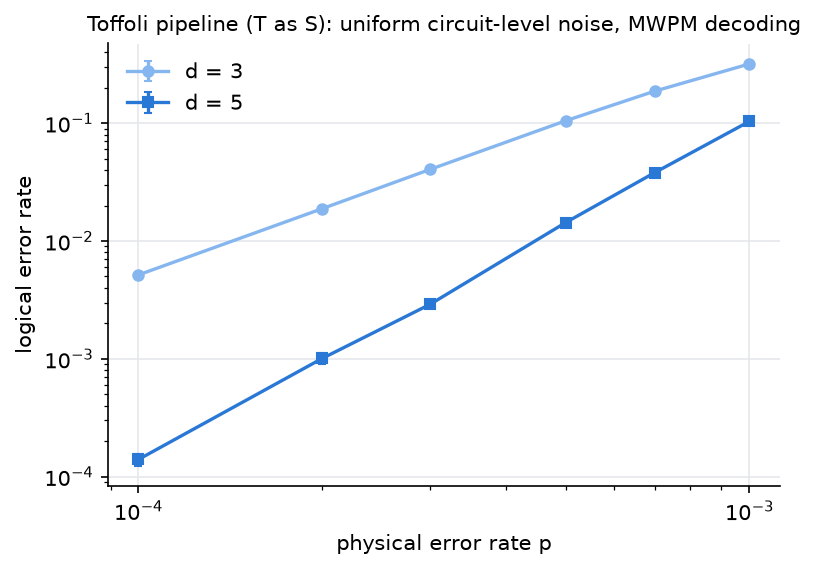

In [13]:
import matplotlib.pyplot as plt

COLOUR = {3: "#86b6ef", 5: "#2a78d6"}
MARKER = {3: "o", 5: "s"}
fig, ax = plt.subplots(figsize=(5.4, 3.9), dpi=150)
for d in DISTANCES:
    ler = np.array([e / s for e, s in results[d]])
    err = np.array([np.sqrt(e) / s for e, s in results[d]])        # Poisson standard error
    ax.errorbar(P_VALUES, ler, yerr=err, color=COLOUR[d], marker=MARKER[d], ms=5, lw=1.6, capsize=2, label=f"d = {d}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("physical error rate p")
ax.set_ylabel("logical error rate")
ax.set_title("Toffoli pipeline (T as S): uniform circuit-level noise, MWPM decoding", fontsize=10)
ax.grid(True, which="major", color="#e5e7eb", linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()